# Exploring Image Preparation and CNN Layers - Géron Chapter 12

**Image example - tower of buddhist incense in China**

A convolutional neural network (CNN) processes images represented as numerical pixel values. It applies filters (kernels) with weights learned during training. Each filter then extracts features from an input image or feature map to identify patterns.

The convolutional layer is the most critical layer in the CNN. Early layers focus on low-level features (edges, texture), while deeper layers combine them into more complex features and shapes.

Pooling layers reduce the size of feature maps by summarising the local regions. They retain useful information and discard the rest, which reduces computational cost but also loses some detail.

The resulting feature maps are then flattened into a single vector and passed through fully connected layers, where a final softmax function converts the output into class probabilities. The class with the highest probability becomes the prediction.

The resulting features support tasks such as image classification, object detection, and face recognition.


IMPORTANT:

- Convolutional layer produces feature maps using filters (kernels = matrix of weights)
- ReLU activation function sets negative values to zero, which introduces non-linearity with no changes to the shape
- Pooling summarises small regions and reduces the feature map's width and height.

### Imports

In [1]:
import numpy as np
import torch
from sklearn.datasets import load_sample_images

sample_images = np.stack(load_sample_images()["images"])
sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255

### Image evalaution

In [2]:
#tensor shape
sample_images.shape

torch.Size([2, 427, 640, 3])

Output: 2 images, 427 pixel, 649 pixel, 3 color channels (RGB)

In [3]:
#Permuting image dimension (Pytorch expects channels first before hight and width)
sample_images_permuted = sample_images.permute(0, 3, 1, 2)
sample_images_permuted.shape

torch.Size([2, 3, 427, 640])

In [4]:
#Cropping images
import torchvision.transforms.v2 as T
cropped_images = T.CenterCrop((70, 120))(sample_images_permuted)
cropped_images.shape

torch.Size([2, 3, 70, 120])

### Convolutional layer

Creating 2D convolutional layer with 32 filters, size 7 x 7 (kernel_size=7) and appling this layer to a small batch of two images. 

NOTE: the layer takes 4D input: 2 dimensions (high + weight) and 1st dimension (batch size) and 2nd dimension (channels)

In [5]:
#Creating 2D convolutional layer and feeding the cropped images into the layer
import torch.nn as nn

torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=7)
fmaps = conv_layer(cropped_images)

In [6]:
fmaps.shape

torch.Size([2, 32, 64, 114])

Output is similar to Input:
- 2 images, 32 channels (output feature maps), we have intensity features for each feature.
- Height and width are downsized (6 pixels lower vertically and horizontally)

In [7]:
# Checking the layer’s parameters
conv_layer.weight.shape

torch.Size([32, 3, 7, 7])

In [8]:
#Checking kernel shape
conv_layer.bias.shape

torch.Size([32])

- Output: 4D (output channels, input channels, kernel height and width)
- The number of output channels = input channels = number of filters => 32

An activation function like ReLU should be added as a next step to learn more complex non-linear relationships. Otherwise, each convolutional layer will perform as a linear transformation.

Flow: image --> convolutional layer --> ReLU --> feature maps passed to the next layer

In [9]:
#Activation function 
activated_fmaps = torch.relu(fmaps)

print(fmaps.shape)
print(activated_fmaps.shape)

torch.Size([2, 32, 64, 114])
torch.Size([2, 32, 64, 114])


### Pooling layer

In [10]:
# Keeps the max in each region 2 x 2
max_pool = nn.MaxPool2d(kernel_size=2)
pooled_images = max_pool(cropped_images)

- Cropped image: [2, 3, 70, 120] --> 2 images , 32 colour channels
- After7 x 7 convolution: [2, 32, 64, 114] --> 2 images , 32 feature maps (no padding)
- After 2 x 2 max pool:  [2, 32, 32, 57] --> same feature maps only half of the weight and width

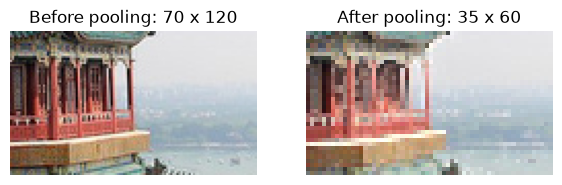

In [11]:
#Visualise image after max_pool (pooling direcly on the image)
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.subplot(1, 2, 1)
plt.imshow(cropped_images[0].permute(1, 2, 0).detach().cpu())
plt.title("Before pooling: 70 x 120")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(pooled_images[0].permute(1, 2, 0).detach().cpu())
plt.title("After pooling: 35 x 60")
plt.axis("off")

plt.show()

The pooled image becomes more blocky after pooling. Max pooling halves the image dimensions, so it reduces the height and width by half. ==> 1/2 x 1/2 = 1/4, leading to a pixel reduction of 1/4.